# How the noise augmentation works

The released `noise` model was trained on clean images **with fake dirt added**, so that messy
backgrounds don't confuse it. This notebook builds that fake dirt one step at a time.

The code is in `hierroute/extra_functions.py` (`add_synthetic_dirt`).

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFilter
from scipy import ndimage

DATA_DIR = Path("/data/Hier-Zooplankton")
CLEAN = DATA_DIR / "Daphnia" / "20240415_Erie_WOS0202_2mm_Rep1_000003_1.tif"
MESSY = [DATA_DIR / "quetico" / "Messy" / "Calanoid" / f"20231007_Kahshahpiwi_Vertical_2mm_rep1_000001_{n}.tif"
         for n in (106, 107, 131, 148)]

rng = random.Random(0)                 # fixed dice, so this notebook gives the same pictures every run
np_rng = np.random.RandomState(0)

def show(*images, titles=(), size=3.2):
    """Show images side by side (grayscale, 0 = black, 255 = white)."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, im, title in zip(np.atleast_1d(axes), images, list(titles) + [""] * len(images)):
        ax.imshow(np.asarray(im), cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. The problem

Most training images have **clean** backgrounds. Some lakes give **messy** ones: debris, fibres,
uneven shading.

A model that has only seen clean backgrounds tends to call a dirty-looking organism "debris".

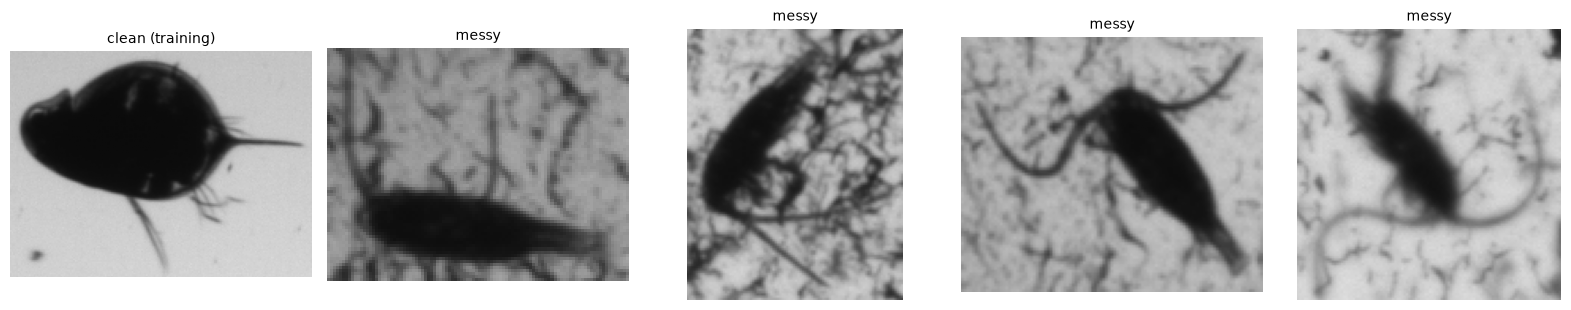

In [2]:
image = Image.open(CLEAN).convert("L")          # training works in grayscale
show(image, *[Image.open(p).convert("L") for p in MESSY],
     titles=["clean (training)", "messy", "messy", "messy", "messy"])

## 2. An image is a grid of numbers

Each pixel is a brightness from **0 (black)** to **255 (white)**. The organism is dark, the background
is light, so the brightness histogram has two humps.

191 x 143 pixels


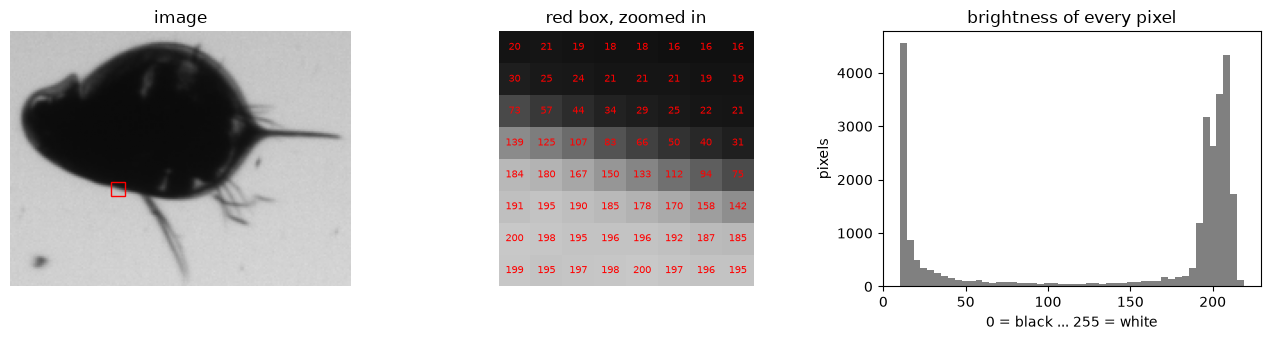

In [3]:
pixels = np.asarray(image, dtype=float)
print(f"{pixels.shape[1]} x {pixels.shape[0]} pixels")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.5))
ax1.imshow(pixels, cmap="gray", vmin=0, vmax=255); ax1.set_title("image"); ax1.axis("off")
windows = [(pixels[y:y + 8, x:x + 8].std(), y, x)          # pick a patch on the organism's edge:
           for y in range(0, pixels.shape[0] - 8, 4)         # the one with the most varied brightness
           for x in range(0, pixels.shape[1] - 8, 4)]
_, y, x = max(windows)
ax1.add_patch(plt.Rectangle((x, y), 8, 8, fill=False, color="red"))
patch = pixels[y:y + 8, x:x + 8]
ax2.imshow(patch, cmap="gray", vmin=0, vmax=255); ax2.set_title("red box, zoomed in"); ax2.axis("off")
for (i, j), v in np.ndenumerate(patch):
    ax2.text(j, i, int(v), ha="center", va="center", fontsize=7, color="red")
ax3.hist(pixels.ravel(), bins=50, color="gray"); ax3.set_title("brightness of every pixel")
ax3.set_xlabel("0 = black ... 255 = white"); ax3.set_ylabel("pixels")
plt.tight_layout(); plt.show()

## 3. Find the organism

The dirt must not cover the organism, so first find it:
1. **Threshold:** pixels clearly darker than average count as "organism".
2. **Biggest blob:** keep only the largest connected piece, dropping stray dark spots.
3. **Safety zone:** grow it by a few pixels; no dirt goes in this zone.

threshold = 120, 7 dark blobs found, safety zone = 11 pixels


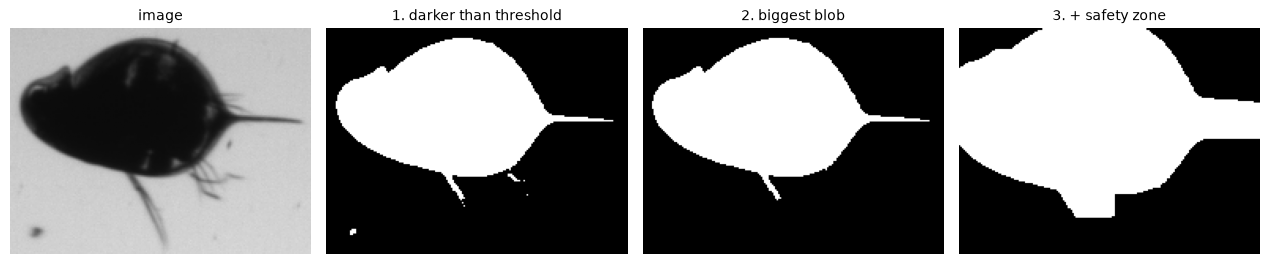

In [4]:
threshold = pixels.mean() - 0.3 * pixels.std()
dark = pixels < threshold

blobs, n_blobs = ndimage.label(dark)                       # number each connected piece
sizes = np.bincount(blobs.ravel()); sizes[0] = 0
organism = blobs == sizes.argmax()

pad = max(2, round(0.08 * min(image.size)))                # 8% of the image's short side
safety_zone = ndimage.binary_dilation(organism, structure=np.ones((2 * pad + 1, 2 * pad + 1)))

print(f"threshold = {threshold:.0f}, {n_blobs} dark blobs found, safety zone = {pad} pixels")
show(image, dark * 255, organism * 255, safety_zone * 255,
     titles=["image", "1. darker than threshold", "2. biggest blob", "3. + safety zone"])

## 4. Add a haze

Messy backgrounds are unevenly shaded. Take random static, blur it heavily into soft blotches, and
darken the image a little under each blotch.

The real effect is very faint (at most 10 out of 255), so the last picture exaggerates it.

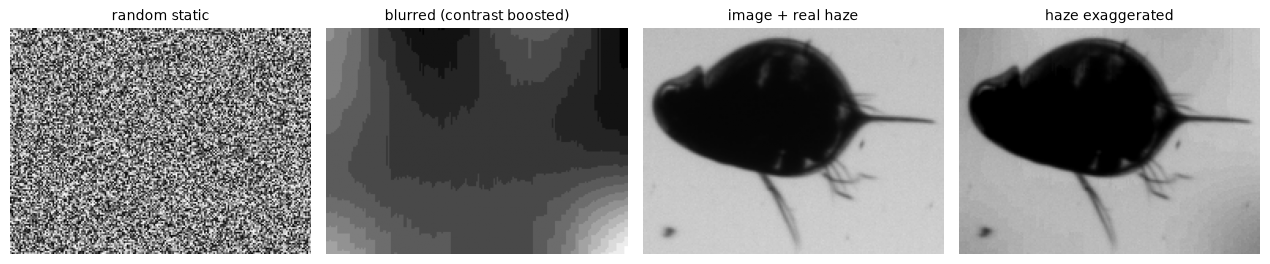

In [5]:
w, h = image.size
static = np_rng.rand(h, w)
blotches = np.asarray(Image.fromarray((static * 255).astype(np.uint8))
                      .filter(ImageFilter.GaussianBlur(radius=w / 6)), dtype=float) / 255

hazed = np.clip(pixels - 10 * blotches, 0, 255)
stretched = (blotches - blotches.min()) / (blotches.max() - blotches.min())   # 0..1, for display only
exaggerated = np.clip(pixels - 80 * stretched, 0, 255)

show(static * 255, stretched * 255, hazed, exaggerated,
     titles=["random static", "blurred (contrast boosted)", "image + real haze", "haze exaggerated"])

## 5. Sprinkle specks

25 tiny dark dots (dust). Each gets a random spot outside the safety zone, plus a random size,
darkness and opacity. They are drawn on a separate, transparent **dirt layer**.

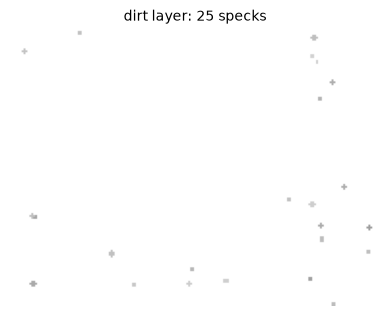

In [6]:
dirt = Image.new("RGBA", (w, h), (0, 0, 0, 0))      # transparent layer (fully see-through)
draw = ImageDraw.Draw(dirt)

def random_spot(x_range=(0, w), y_range=(0, h)):
    """A random position, re-rolled (up to 10 times) if it lands in the safety zone."""
    for _ in range(10):
        x, y = rng.uniform(*x_range), rng.uniform(*y_range)
        if not safety_zone[min(int(y), h - 1), min(int(x), w - 1)]:
            break
    return x, y

for _ in range(25):
    x, y = random_spot()
    r = rng.uniform(0.3, 1.2)                                  # radius in pixels
    gray, opacity = rng.randint(40, 110), rng.randint(60, 120)  # 0 = black / see-through, 255 = white / solid
    draw.ellipse([x - r, y - r, x + r, y + r], fill=(gray, gray, gray, opacity))

def on_white(layer):
    return Image.alpha_composite(Image.new("RGBA", layer.size, (255, 255, 255, 255)), layer).convert("L")

show(on_white(dirt), titles=["dirt layer: 25 specks"], size=4)

## 6. Draw fibres

8 short lines that bend a little (hairs, fibres). Real fibres tend to sit near the organism, so 3 in 4
start inside the box around it (still outside the safety zone).

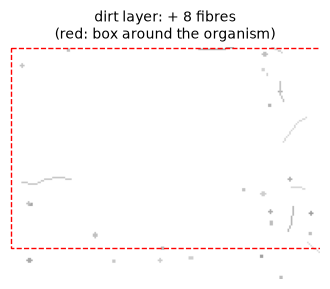

In [7]:
ys, xs = np.nonzero(organism)
x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
px, py = 0.15 * (x1 - x0), 0.15 * (y1 - y0)                 # box around the organism, 15% padding
box = (max(0, x0 - px), max(0, y0 - py), min(w, x1 + px), min(h, y1 + py))

for _ in range(8):
    if rng.random() < 0.75:
        start = random_spot((box[0], box[2]), (box[1], box[3]))   # near the organism
    else:
        start = random_spot()                                     # anywhere
    length, angle = rng.uniform(8, 35), rng.uniform(0, 2 * np.pi)
    points = [start]
    for _ in range(rng.randint(2, 4)):                            # a few segments, each turning a bit
        angle += rng.uniform(-0.5, 0.5)
        points.append((points[-1][0] + length / 3 * np.cos(angle), points[-1][1] + length / 3 * np.sin(angle)))
    gray, opacity = rng.randint(50, 120), rng.randint(55, 110)
    draw.line(points, fill=(gray, gray, gray, opacity), width=1)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(on_white(dirt), cmap="gray", vmin=0, vmax=255)
ax.add_patch(plt.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, color="red", ls="--"))
ax.set_title("dirt layer: + 8 fibres\n(red: box around the organism)", fontsize=10); ax.axis("off"); plt.show()

## 7. Soften the dirt and lay it on

Dirt floating away from the organism is out of focus, so blur the dirt layer slightly, then lay it over
the hazed image.

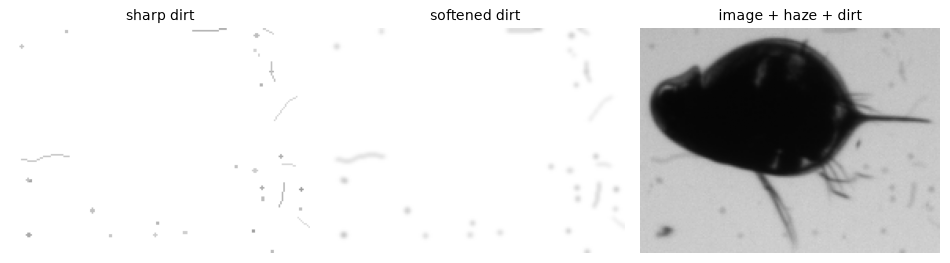

In [8]:
soft_dirt = dirt.filter(ImageFilter.GaussianBlur(radius=1.2))

hazed_img = Image.fromarray(hazed.astype(np.uint8)).convert("RGBA")
dirty = Image.alpha_composite(hazed_img, soft_dirt).convert("L")

show(on_white(dirt), on_white(soft_dirt), dirty, titles=["sharp dirt", "softened dirt", "image + haze + dirt"])

## 8. Put the organism back, untouched

The haze and blur can bleed onto the organism. As a last step, copy the **original** organism pixels
back over, using the safety zone as a stencil (with a soft edge, so there's no visible seam).

The organism ends up exactly as it was; only the background changed.

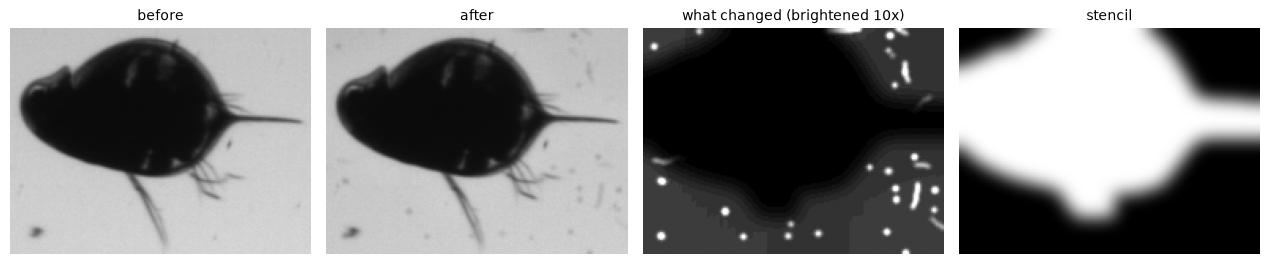

organism pixels changed: 0 of 8568


In [9]:
stencil = Image.fromarray((safety_zone * 255).astype(np.uint8)).filter(
    ImageFilter.GaussianBlur(radius=max(1, pad // 2)))
final = Image.composite(image, dirty, stencil)               # stencil white -> original, black -> dirty

changed = np.abs(np.asarray(final, dtype=float) - pixels)
show(image, final, changed * 10, stencil, titles=["before", "after", "what changed (brightened 10x)", "stencil"])
print(f"organism pixels changed: {int((changed[organism] > 0).sum())} of {int(organism.sum())}")

## 9. The same in one line

`add_synthetic_dirt` does steps 3 to 8. Every call rolls new dice, so the same image gets different dirt
each time.

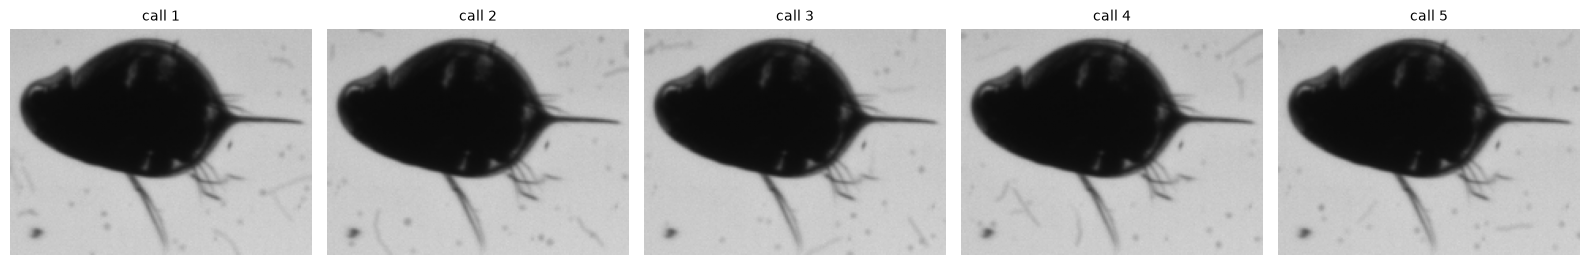

In [10]:
from hierroute.extra_functions import add_synthetic_dirt

show(*[add_synthetic_dirt(image).convert("L") for _ in range(5)], titles=["call 1", "call 2", "call 3", "call 4", "call 5"])

## 10. What the model sees during training

Each time a training image is loaded, it goes through these steps in order:
1. add dirt, with an 80% chance (`RandomBackgroundNoise(p=0.8)`)
2. random left-right and up-down flips
3. shrink to 64 x 64 pixels

Over 40 epochs the model sees each organism about 40 times, each time with different dirt, and learns
that the dirt doesn't matter.

Compose(
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


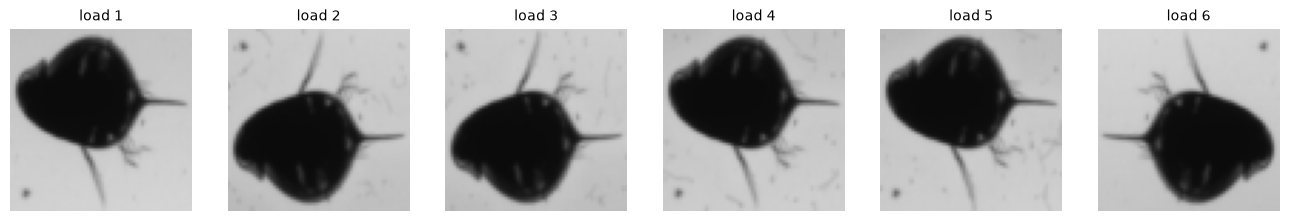

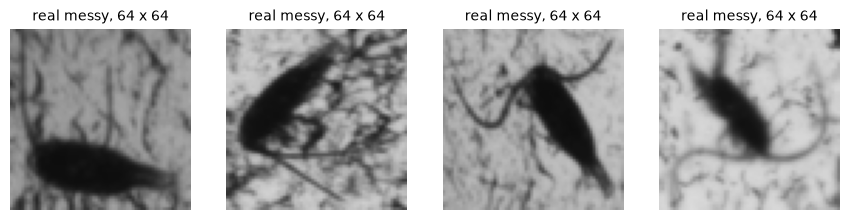

In [11]:
from hierroute.config import TRAIN_DEFAULTS
from hierroute.train import build_train_transforms

augment = build_train_transforms(TRAIN_DEFAULTS)
print(augment)
seen = [(augment(image)[0].numpy() * 255) for _ in range(6)]       # 64 x 64, as the model gets it
show(*seen, titles=[f"load {i + 1}" for i in range(6)], size=2.2)

real = [np.asarray(Image.open(p).convert("L").resize((64, 64))) for p in MESSY]
show(*real, titles=["real messy, 64 x 64"] * 4, size=2.2)

The fake dirt is lighter than these real examples: its amount was tuned to match an average messy
background, not the worst ones.

## 11. Did it help?

Quetico test sets, released models (`swin_t_cnn_baseline_10-20` without the dirt, `swin_t_cnn_noise_10-20`
with it). Zooplankton particles only:

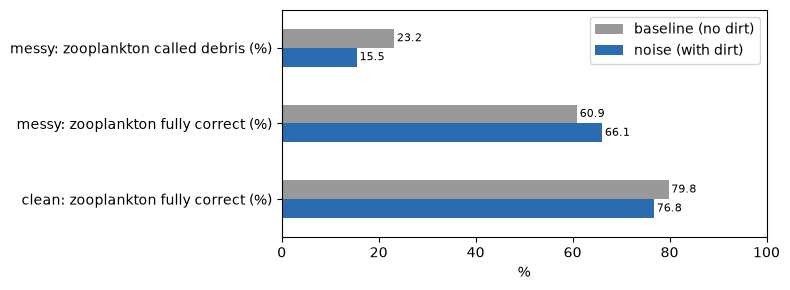

,baseline (no dirt),noise (with dirt)
messy: zooplankton called debris (%),23.2,15.5
messy: zooplankton fully correct (%),60.9,66.1
clean: zooplankton fully correct (%),79.8,76.8


In [12]:
import pandas as pd

results = pd.DataFrame({
    "baseline (no dirt)":   [23.2, 60.9, 79.8],
    "noise (with dirt)":    [15.5, 66.1, 76.8],
}, index=["messy: zooplankton called debris (%)",
          "messy: zooplankton fully correct (%)",
          "clean: zooplankton fully correct (%)"])

ax = results.plot.barh(figsize=(8, 3), color=["#999999", "#2b6cb0"])
ax.invert_yaxis(); ax.set_xlabel("%"); ax.set_xlim(0, 100); ax.legend(loc="upper right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()
results

- **Messy backgrounds:** far fewer zooplankton are written off as debris (23% → 16%), and more are fully
  correct (61% → 66%).
- **Clean backgrounds:** a small cost (80% → 77%).

That trade-off is why both models are released: `noise` for messy samples, `baseline` for clean ones.